# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 **without ImageNet pretraining and without tuning** (`NO_TUNING_ARCH_HYPERPARAMS["resnet18"]`), then saves its results and weights to disk for the results notebook. This is the baseline role AlexNet used to play — see `wwtw_utils.py`'s `ARCH_HYPERPARAMS` comment for why the baseline is now the *same* architecture as the tuned, pretrained `resnet18` run rather than a different one.


In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): CapeFlats
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 846 | Val: 205 | Test: 1476


## Build dataloaders + class weights for this architecture

In [2]:
cfg = NO_TUNING_ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (ResNet-18, trained from scratch)

In [3]:
# ---------------------------------------------------------
# Define the CNN (ResNet-18, trained from scratch — no ImageNet weights)
# ---------------------------------------------------------
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18 (scratch)] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.1642 acc 0.485 | val loss 0.8686 acc 0.620 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 0.9699 acc 0.598 | val loss 0.8064 acc 0.678 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.9299 acc 0.621 | val loss 0.8624 acc 0.737


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.9256 acc 0.563 | val loss 1.0004 acc 0.566


...

[ResNet-18 (scratch)] Epoch  36/100 | LR: 1.00e-06 | train loss 0.5550 acc 0.719 | val loss 0.5045 acc 0.751


[ResNet-18 (scratch)] Epoch  37/100 | LR: 1.00e-06 | train loss 0.5276 acc 0.747 | val loss 0.4993 acc 0.746


[ResNet-18 (scratch)] Epoch  38/100 | LR: 1.00e-06 | train loss 0.4808 acc 0.771 | val loss 0.4973 acc 0.756


[ResNet-18 (scratch)] Epoch  39/100 | LR: 1.00e-06 | train loss 0.5080 acc 0.754 | val loss 0.5002 acc 0.741


[ResNet-18 (scratch)] Epoch  40/100 | LR: 1.00e-06 | train loss 0.5170 acc 0.742 | val loss 0.4932 acc 0.761

[ResNet-18 (scratch)] No val loss improvement for 10 epochs — stopping early at epoch 40.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.4921)


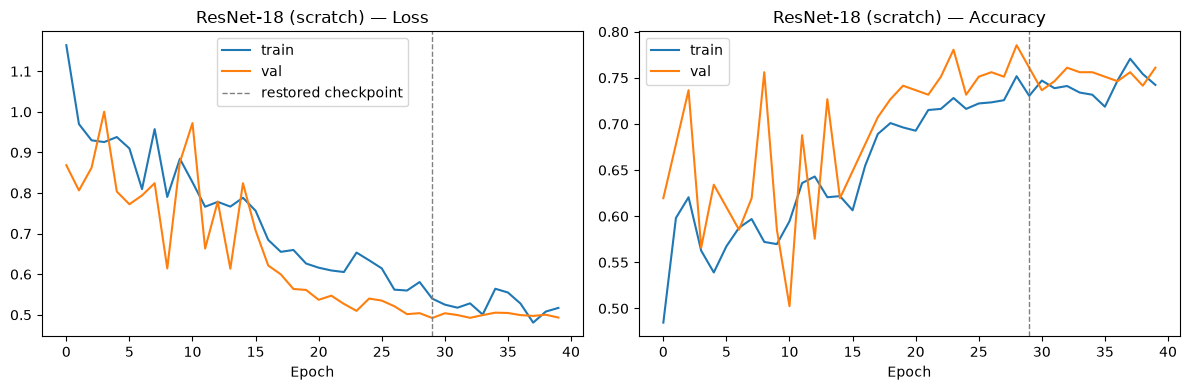

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.537


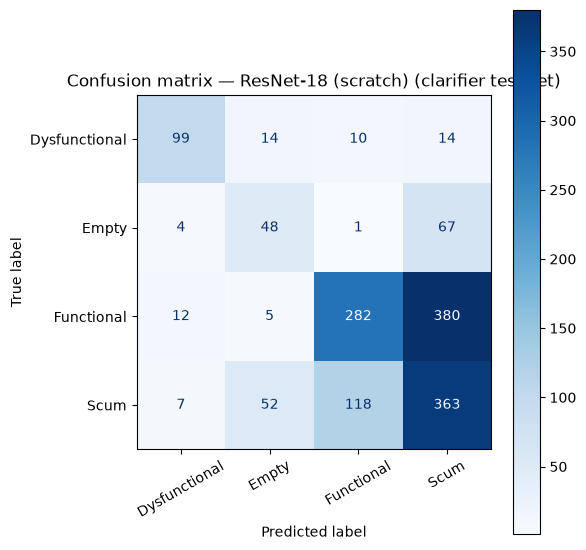

               precision    recall  f1-score   support

Dysfunctional      0.811     0.723     0.764       137
        Empty      0.403     0.400     0.402       120
   Functional      0.686     0.415     0.517       679
         Scum      0.441     0.672     0.532       540

     accuracy                          0.537      1476
    macro avg      0.585     0.553     0.554      1476
 weighted avg      0.585     0.537     0.536      1476



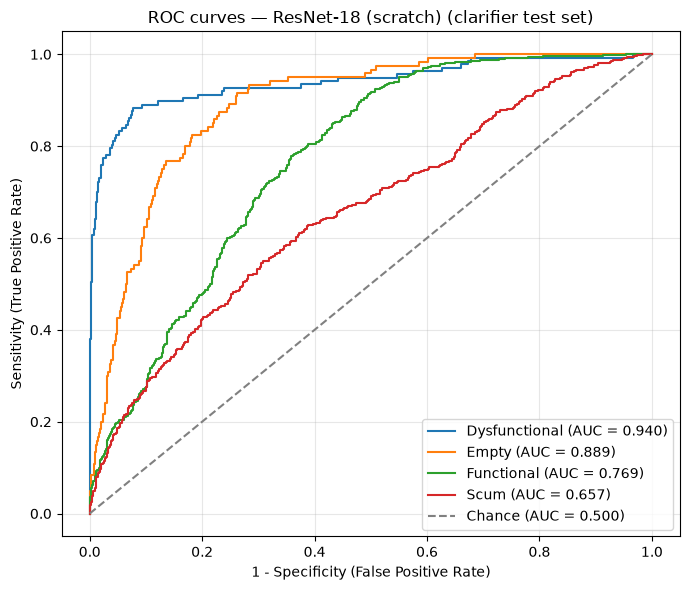

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.940
  Empty          : 0.889
  Functional     : 0.769
  Scum           : 0.657

Mean AUC (over 4/4 classes with test examples): 0.814


(np.float64(0.5365853658536586),
 {'Dysfunctional': 0.9398995873377561,
  'Empty': 0.8887168141592922,
  'Functional': 0.7693319757633097,
  'Scum': 0.6574430199430199})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_CapeFlats.pkl
Saved model weights to ../models/pad/clarifier_resnet18_scratch_cnn.pt
